<h1 align="center">Binary Logistic Regression</h1>
<h3 align="center">Implementation Using NumPy and the Two Moons Dataset</h3>

# 1. Linear Equation

$$
z_i = \mathbf{x}_i^T\mathbf{w} + b
$$

# 2. Sigmoid Function

$$
p_i = \sigma(z_i) = \frac{1}{1+e^{-z_i}}
$$

# 3. Binary Cross-Entropy (Log Loss)

$$
J(w,b) = -\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

# 4. Gradient Descent

#### Calculate Gradients

$$
\nabla_{\mathbf{w}}J =
\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)\mathbf{x}_i
$$

$$
\frac{\partial J}{\partial b}
= \frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)
$$

# Update Weight and Bias

$$
\mathbf{w} = \mathbf{w} - \alpha \nabla_{\mathbf{w}}J
$$

$$
b = b - \alpha \frac{\partial J}{\partial b}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
data, target = make_moons()

X_Train,X_Test,Y_Train,Y_Test = train_test_split(data,target,test_size=0.2)

In [120]:
from scipy.special import expit

W = np.random.rand(X_Train.shape[1])
B = np.random.rand()

lr = 0.7
eps = 10**-12
loss_Function = []

for i in range(300):
    Z = X_Train @ W + B
    P = 1/(1+np.exp(-Z))

    BCELL = -np.mean(
        Y_Train * np.log(P + eps) +
        (1 - Y_Train) * np.log(1 - P + eps)
    )

    loss_Function.append(BCELL)

    dW = ((P - Y_Train) @ X_Train)/len(X_Train)
    dB = np.mean(P - Y_Train)

    W = W - lr * dW

    B = B - lr * dB

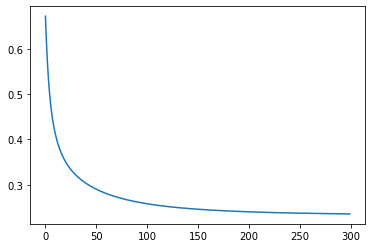

In [121]:
plt.plot(loss_Function)

In [122]:
# Prediction
YT  = X_Test @ W + B
PT   =1/(1+np.exp(-YT))
YpredM = (PT>0.5).astype(int)
print("Predicted Matrix:",YpredM,'\n',"Real Matrix:    ",Y_Test)

Predicted Matrix: [0 1 0 0 1 0 1 1 1 0 1 0 1 1 0 0 1 1 1 1] 
 Real Matrix:     [0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 1 0]


In [123]:
ACC = accuracy_score(Y_Test,YpredM)
print(f"Accuracy:{ACC:.2%}")

Accuracy:75.00%


# Implementation via Sklearn libraries

In [127]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
model = LogisticRegression(penalty=None)
model.fit(X_Train, Y_Train)
Ypred = model.predict(X_Test)
print("Predicted Matrix:", Ypred)
print("Real Matrix:     ", Y_Test)
ACC = accuracy_score(Y_Test, Ypred)
print(f"Accuracy: {ACC:.2%}")

Predicted Matrix: [0 1 0 0 1 0 1 1 1 0 1 0 1 1 0 0 1 1 1 1]
Real Matrix:      [0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 1 0]
Accuracy: 75.00%
